# 00 · Аудит генерации синтетических данных

**Курсовая:** прогнозирование шестилетнего риска рака лёгких на синтетических данных.

**Цель ноутбука:** сравнить реконструированный генератор `article_legacy` с новым `baseline` до начала обучения моделей.

### Исследовательские вопросы

1. Устраняет ли `baseline` противоречия в истории курения, выявленные в `article_legacy`?
2. Как изменяются распределения признаков, вероятности риска и доля положительного класса?
3. Какие различия связаны с **генерацией признаков** $P(X)$, а какие — с **механизмом формирования метки** $P(Y \mid X)$?

**Границы эксперимента:** это проверка корректности симуляции, **не** клиническая валидация. На данном этапе ML-модели не обучаются.

## 1. Подготовка окружения и импорт

Запусти Jupyter из корня репозитория или открой ноутбук из папки `notebooks/`. Ячейка ниже находит корень проекта **без абсолютных путей**, чтобы импортировать локальные модули `src/`. Выбери ядро `Python (lung-cancer-ml)`.

In [4]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from scipy.special import expit

project_root = Path.cwd().resolve()
if not (project_root / "src" / "data_generation.py").is_file():
    project_root = project_root.parent
if not (project_root / "src" / "data_generation.py").is_file():
    raise FileNotFoundError(
        "Не найден src/data_generation.py. Открой ноутбук из корня проекта или notebooks/."
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_generation import generate_article_legacy, generate_baseline

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Корень проекта:", project_root)

Matplotlib is building the font cache; this may take a moment.


Python: 3.11.11
NumPy: 2.4.6
Pandas: 3.1.1
Корень проекта: /Users/dyadyundanil/Documents/lung-cancer-ml-study


## 2. Генерация и контракт данных

Используем **одинаковые** `n` и `seed`, но **не** предполагаем, что строки в двух таблицах соответствуют одним и тем же людям: `legacy` использует `RandomState`, а `baseline` — `default_rng`, и порядок генерации признаков отличается.

В обеих таблицах есть признаки пациента и служебные колонки `logit_base`, `logit_true`, `risk`, `y`. В будущих экспериментах **нельзя** использовать `logit_base`, `logit_true`, `risk` как признаки — это утечка механизма формирования целевой переменной.

In [7]:
N = 10_000
SEED = 42

FEATURE_COLUMNS = [
    "age", "bmi", "education", "copd", "personal_cancer",
    "family_lung_cancer", "is_current_smoker", "cigs_per_day",
    "smoking_years", "quit_years", "race",
]
SERVICE_COLUMNS = ["logit_base", "logit_true", "risk", "y"]

legacy = generate_article_legacy(n=N, seed=SEED)
baseline = generate_baseline(n=N, seed=SEED)

for name, df in [("article_legacy", legacy), ("baseline", baseline)]:
    assert len(df) == N, f"Неверное число строк: {name}"
    assert set(FEATURE_COLUMNS + SERVICE_COLUMNS).issubset(df.columns)
    assert df["y"].isin([0, 1]).all()
    assert df["risk"].between(0, 1).all()

print("Форма legacy:", legacy.shape)
print("Форма baseline:", baseline.shape)
display(baseline[FEATURE_COLUMNS].head(5))

Форма legacy: (10000, 15)
Форма baseline: (10000, 15)


,age,bmi,education,copd,personal_cancer,family_lung_cancer,is_current_smoker,cigs_per_day,smoking_years,quit_years,race
0,56,25.917217,4,0,0,0,0,7,24,17,White
1,70,21.674205,4,0,0,0,1,2,36,0,White
2,68,27.796567,3,0,0,0,1,2,40,0,Asian
3,63,23.380634,4,0,0,0,0,9,25,18,White
4,63,19.978590,4,0,0,0,0,1,24,11,White


## 3. Проверка логической согласованности

Проверяем особенности, обнаруженные при аудите исторического генератора:

- текущий курильщик с `quit_years > 0` — логическое противоречие;
- бывший курильщик с `quit_years = 0` — противоречит **принятому правилу нового генератора** (в реальности дробное время после отказа может быть менее года);
- предполагаемый возраст начала курения `age - smoking_years - quit_years < 15` — нарушение **условной границы симуляции**, а не универсального клинического правила;
- `smoking_years + quit_years > age` — невозможная история;
- пропуски и некорректные вероятности.

In [12]:
def audit_generator(df: pd.DataFrame, name: str) -> dict:
    current = df["is_current_smoker"].eq(1)
    former = ~current
    start_age = df["age"] - df["smoking_years"] - df["quit_years"]

    return {
        "Генератор": name,
        "Объектов": len(df),
        "Положительных y": int(df["y"].sum()),
        "Доля y=1, %": 100 * df["y"].mean(),
        "Средний истинный риск, %": 100 * df["risk"].mean(),
        "Текущие: quit_years > 0": int((current & df["quit_years"].gt(0)).sum()),
        "Бывшие: quit_years = 0": int((former & df["quit_years"].eq(0)).sum()),
        "Возраст начала < 15": int((start_age < 15).sum()),
        "Стаж + отказ > возраст": int(
            (df["smoking_years"] + df["quit_years"] > df["age"]).sum()
        ),
        "Пропусков": int(df.isna().sum().sum()),
        "Некорректных risk": int((~np.isfinite(df["risk"]) | ~df["risk"].between(0, 1)).sum()),
    }

audit = pd.DataFrame([
    audit_generator(legacy, "article_legacy"),
    audit_generator(baseline, "baseline"),
]).set_index("Генератор")
display(audit.T.round(3))

Генератор,article_legacy,baseline
Объектов,10000.00,10000.000
Положительных y,121.00,86.000
"Доля y=1, %",1.21,0.860
"Средний истинный риск, %",1.22,0.809
Текущие: quit_years > 0,1607.00,0.000
Бывшие: quit_years = 0,3708.00,0.000
Возраст начала < 15,1041.00,0.000
Стаж + отказ > возраст,89.00,0.000
Пропусков,0.00,0.000
Некорректных risk,0.00,0.000


**Интерпретация:** нули в проверках `baseline` означают, что новые ограничения реализованы корректно. Они **не** доказывают реалистичность совместного распределения признаков: например, ХОБЛ здесь по-прежнему генерируется независимо от истории курения.

Для `legacy` нарушения **ожидаемы**: этот код сохранён без исправлений для реконструкции предыдущего эксперимента.

## 4. Распределения признаков $P(X)$

Сравним характеристики с одинаковыми названиями в двух выборках. Гистограммы нормированы на площадь (параметр `density=True`), поэтому различия в форме не зависят от размера набора. Для наглядности строим несколько отдельных графиков.

In [22]:
summary_features = [
    "age", "bmi", "cigs_per_day", "smoking_years",
    "quit_years", "is_current_smoker", "copd",
]
feature_summary = pd.DataFrame({
    "article_legacy": legacy[summary_features].mean(),
    "baseline": baseline[summary_features].mean(),
})
feature_summary["Разность baseline - legacy"] = (
    feature_summary["baseline"] - feature_summary["article_legacy"]
)
display(feature_summary.round(3))

,article_legacy,baseline,Разность baseline - legacy
age,64.534,64.426,-0.109
bmi,26.996,26.954,-0.041
cigs_per_day,9.462,9.551,0.089
smoking_years,29.643,28.647,-0.996
quit_years,3.863,5.839,1.976
is_current_smoker,0.402,0.404,0.003
copd,0.152,0.150,-0.001


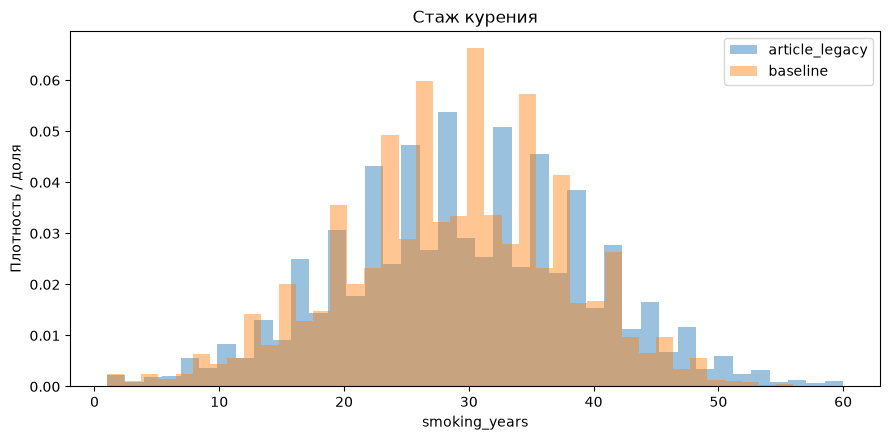

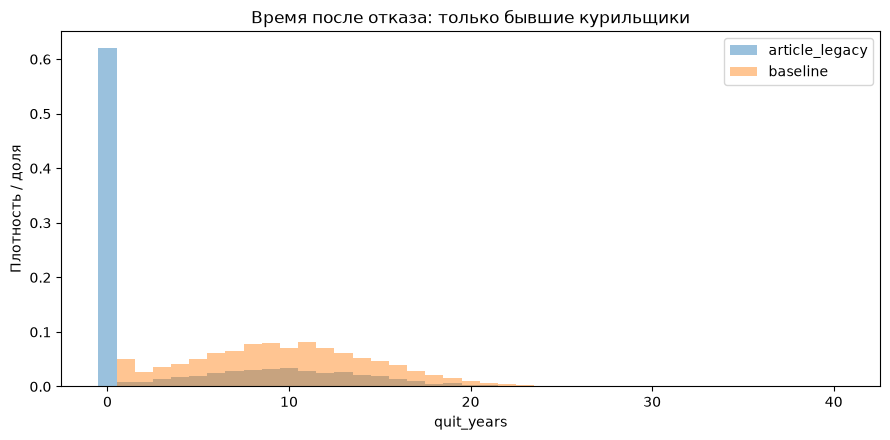

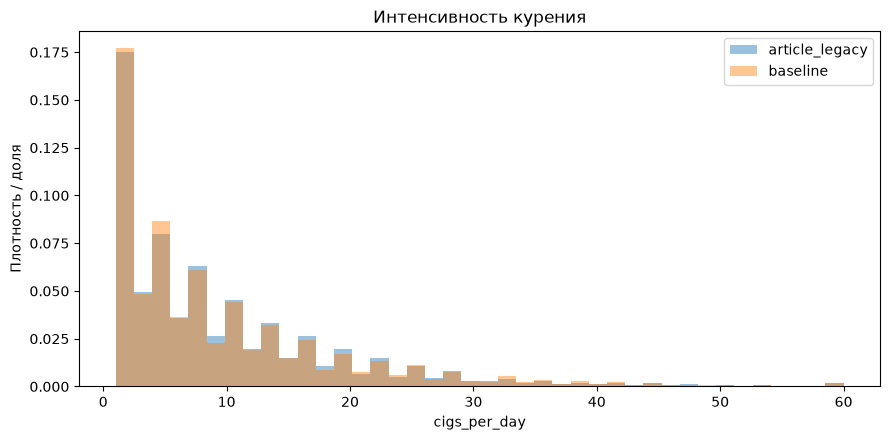

In [28]:
def compare_histograms(column: str, title: str, bins=40, subset=None):
    old = legacy if subset is None else legacy.loc[subset(legacy)]
    new = baseline if subset is None else baseline.loc[subset(baseline)]
    plt.figure(figsize=(9, 4.5))
    plt.hist(old[column], bins=bins, alpha=0.45, density=True, label="article_legacy")
    plt.hist(new[column], bins=bins, alpha=0.45, density=True, label="baseline")
    plt.xlabel(column)
    plt.ylabel("Плотность / доля")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

compare_histograms("smoking_years", "Стаж курения", bins=40)
compare_histograms(
    "quit_years", "Время после отказа: только бывшие курильщики",
    bins=np.arange(-0.5, 41.5, 1),
    subset=lambda df: df["is_current_smoker"].eq(0),
)
compare_histograms("cigs_per_day", "Интенсивность курения", bins=40)

Особенность: даже когда исходные распределения похожи, новый генератор ограничивает `smoking_years` сверху величиной `age - 15 - quit_years`. Поэтому некоторые распределения могут измениться вследствие введения ограничений. Отдельно можно проверить доли категорий `race`, но их вероятности здесь являются **заданными параметрами симуляции**, а не оценками популяционной структуры.

## 5. Истинные вероятности и наблюдаемая частота положительного класса

`risk` — вычисленная для каждого пациента вероятность события за шестилетний горизонт модели. `y` — случайная реализация `Bernoulli(risk)`.

Поэтому $\overline{y}$ не обязана в точности совпадать с $\overline{risk}$ даже на одной выборке. При редком событии различие в десятки случаев может быть заметным.

,Генератор,"Средний риск, %","Наблюдаемая доля y=1, %",Число y=1
0,article_legacy,1.220,1.21,121
1,baseline,0.809,0.86,86


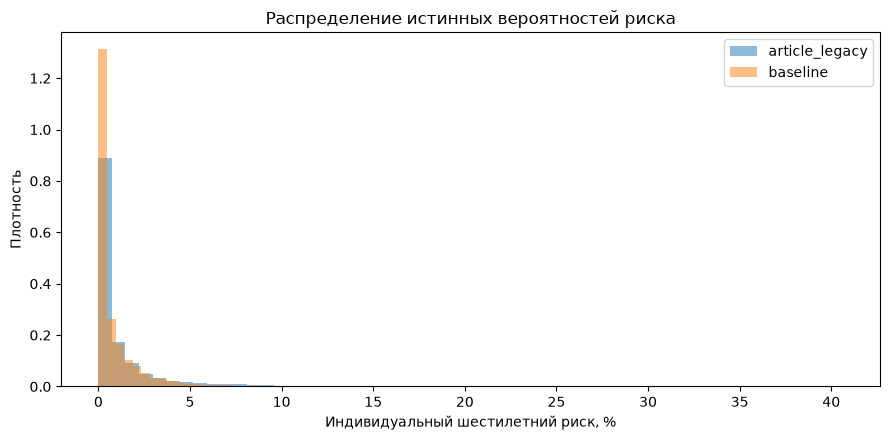

In [33]:
prevalence_comparison = pd.DataFrame({
    "Генератор": ["article_legacy", "baseline"],
    "Средний риск, %": [100 * legacy["risk"].mean(), 100 * baseline["risk"].mean()],
    "Наблюдаемая доля y=1, %": [100 * legacy["y"].mean(), 100 * baseline["y"].mean()],
    "Число y=1": [int(legacy["y"].sum()), int(baseline["y"].sum())],
})
display(prevalence_comparison.round(3))

plt.figure(figsize=(9, 4.5))
plt.hist(100 * legacy["risk"], bins=55, alpha=0.5, density=True, label="article_legacy")
plt.hist(100 * baseline["risk"], bins=55, alpha=0.5, density=True, label="baseline")
plt.xlabel("Индивидуальный шестилетний риск, %")
plt.ylabel("Плотность")
plt.title("Распределение истинных вероятностей риска")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Контролируемое сравнение механизмов $P(Y \mid X)$

**Почему нельзя сказать, что изменение доли `y=1` вызвано только «исправлением генерации»?** Между `legacy` и `baseline` изменились одновременно:

- формирование признаков $P(X)$;
- член `quit_years` для активных курильщиков в расчёте логита;
- наличие искусственного взаимодействия \(+1.2\) при `age > 65` и текущем курении;
- генератор псевдослучайных чисел.

Чтобы хотя бы отдельно увидеть влияние **формулы риска**, возьмём **один и тот же набор признаков из `baseline`** и рассчитаем три варианта $P(Y \mid X)$. Для активных курильщиков на согласованных данных разность опубликованного и реконструированного логитов равна \(+0.308572\), а для бывших равна нулю.

Это сравнение математических механизмов **на одинаковом X**. Оно не является причинной оценкой медицинских эффектов.

In [37]:
current_mask = baseline["is_current_smoker"].eq(1).to_numpy()
old_age_current_mask = (
    baseline["age"].gt(65).to_numpy() & current_mask
)

published_logit = baseline["logit_base"].to_numpy()
legacy_formula_logit = published_logit - 0.308572 * current_mask
legacy_with_interaction_logit = (
    legacy_formula_logit + 1.2 * old_age_current_mask
)

same_x_comparison = pd.DataFrame({
    "Механизм": [
        "Опубликованная PLCOm2012",
        "Реконструированная формула без +1.2",
        "Реконструированная формула с +1.2",
    ],
    "Средний риск на одном X, %": [
        100 * expit(published_logit).mean(),
        100 * expit(legacy_formula_logit).mean(),
        100 * expit(legacy_with_interaction_logit).mean(),
    ],
})
display(same_x_comparison.round(3))

assert np.allclose(expit(published_logit), baseline["risk"].to_numpy())

,Механизм,"Средний риск на одном X, %"
0,Опубликованная PLCOm2012,0.809
1,Реконструированная формула без +1.2,0.698
2,Реконструированная формула с +1.2,1.099


## 7. Результаты и выводы

После запуска всех ячеек ниже будет автоматически сформирована краткая сводка по текущим параметрам `N` и `SEED`. Её можно использовать как основу для текстовых выводов в курсовой.

In [46]:
legacy_bad = int(audit.loc["article_legacy", "Текущие: quit_years > 0"])
baseline_bad = int(audit.loc["baseline", "Текущие: quit_years > 0"])
legacy_cases = int(legacy["y"].sum())
baseline_cases = int(baseline["y"].sum())

display(Markdown(f"""
### Краткое резюме при `n={N:,}`, `seed={SEED}`

- **Согласованность:** у `article_legacy` обнаружено **{legacy_bad}** текущих курильщиков
  с `quit_years > 0`, у нового `baseline` — **{baseline_bad}**.
- **Положительный класс:** в `article_legacy` — **{legacy_cases}** случаев (`{100*legacy['y'].mean():.2f}%`),
  в `baseline` — **{baseline_cases}** (`{100*baseline['y'].mean():.2f}%`).
- **Средний истинный риск:** `article_legacy` — **{100*legacy['risk'].mean():.3f}%**,
  `baseline` — **{100*baseline['risk'].mean():.3f}%**.
- **Оговорка:** разницу между сценариями нельзя приписать одному изменению,
  поскольку различаются и распределения X, и генераторы случайных чисел,
  и формулы риска. Контролируемое сравнение на одинаковом X приведено в разделе 6.
"""))


### Краткое резюме при `n=10,000`, `seed=42`

- **Согласованность:** у `article_legacy` обнаружено **1607** текущих курильщиков
  с `quit_years > 0`, у нового `baseline` — **0**.
- **Положительный класс:** в `article_legacy` — **121** случаев (`1.21%`),
  в `baseline` — **86** (`0.86%`).
- **Средний истинный риск:** `article_legacy` — **1.220%**,
  `baseline` — **0.809%**.
- **Оговорка:** разницу между сценариями нельзя приписать одному изменению,
  поскольку различаются и распределения X, и генераторы случайных чисел,
  и формулы риска. Контролируемое сравнение на одинаковом X приведено в разделе 6.


### Ограничения и следующий шаг

1. `baseline` гарантирует выбранные логические правила истории курения, но **не** воспроизводит реалистичное совместное распределение всех признаков: ХОБЛ и многие другие характеристики по-прежнему генерируются независимо.
2. Некоторые критерии согласованности (например, возраст начала курения ≥ 15) — **наши исследовательские допущения**, а не клинические нормативы.
3. `article_legacy` — **реконструированный** исходник предыдущего исследования; полная идентичность историческому коду не доказана.
4. Оба датасета синтетические; никакие результаты этого ноутбука не доказывают качество медицинского прогноза на реальных пациентах.
5. На следующем этапе будем сравнивать модели на сценариях с заранее определённой процедурой train/validation/test. Служебные поля `risk`, `logit_base`, `logit_true` никогда не станут признаками ML-моделей.